In [3]:
import pickle
# add multipoles package path
import sys
# sys.path.append('/Users/nem0x/Documents/Pyckages')
# from Electrodes.multipoles import MultipoleControl

# %pip install --upgrade --force-reinstall vtk pyvista

%matplotlib inline
import numpy as np
import pandas as pd
from itertools import compress
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, InsetPosition, mark_inset, zoomed_inset_axes
from ipywidgets import interactive, interact
import ipywidgets as widgets

import sys
sys.path.append('/Users/ozgur/GithubDesktop/PaulTrapAnalysis/')
# print(sys.path)
from PaulTrapAnalysis.components.Electrode import SimulatedElectrode
from PaulTrapAnalysis.components.Trap import Trap
from PaulTrapAnalysis.components.Multipoles import MultipoleControl

import PaulTrapAnalysis.components.Multipoles as m
print(m.__file__)


/Users/ozgur/GithubDesktop/PaulTrapAnalysis/PaulTrapAnalysis/components/Multipoles.py


# define some useful functions

In [4]:
def find_nearest(array, value):
    array = np.asarray(array)
    idx = (np.abs(array - value)).argmin()
    return array[idx]

def add_value_labels(ax, spacing=5):
    """Add labels to the end of each bar in a bar chart.

    Arguments:
        ax (matplotlib.axes.Axes): The matplotlib object containing the axes
            of the plot to annotate.
        spacing (int): The distance between the labels and the bars.
    """

    # For each bar: Place a label
    for rect in ax.patches:
        # Get X and Y placement of label from rect.
        y_value = rect.get_height()
        x_value = rect.get_x() + rect.get_width() / 2

        # Number of points between bar and label. Change to your liking.
        space = spacing
        # Vertical alignment for positive values
        va = 'bottom'

        # If value of bar is negative: Place label below bar
        if y_value < 0:
            # Invert space to place label below
            space *= -1
            # Vertically align label at top
            va = 'top'

        # Use Y value as label and format number with one decimal place
        label = "{:.3f}".format(y_value)

        # Create annotation
        ax.annotate(
            label,                      # Use `label` as label
            (x_value, y_value),         # Place label at end of the bar
            xytext=(0, space),          # Vertically shift label by `space`
            textcoords="offset points", # Interpret `xytext` as offset in points
            ha='center',                # Horizontally center label
            va=va)                      # Vertically align label differently for
                                        # positive and negative values.

# import data, and define parameters

In [5]:
# path = './3D_design_v7_newformat.pkl'
# f = open(path,'rb')
# trap = pickle.load(f)
prefix = 'vtks/horizontal_10_pathway_mirror_inventor_'
electrode_list = [
                        #  'DC0', 
                         'DC1', 'DC2', 'DC3', 'DC4', 'DC5', 'DC6', 'DC7', 'DC8', 'DC9', 'DC10', 'DC11', 'DC12', 'DC13', 'DC14', 'DC15', 'DC16',
                         'RF1', 'RF2' 
                        ]
print(electrode_list)
trap = Trap()
for elec in electrode_list:
    print(elec)
    trap.update_electrodes(SimulatedElectrode.from_vtk(elec_name = elec, scale = 10, file = prefix + elec + '.vtk'))

# rf1 = SimulatedElectrode.from_vtk(elec_name = "RF1", file = "3D_design_v7_color_custom_RF1.vtk")

['DC1', 'DC2', 'DC3', 'DC4', 'DC5', 'DC6', 'DC7', 'DC8', 'DC9', 'DC10', 'DC11', 'DC12', 'DC13', 'DC14', 'DC15', 'DC16', 'RF1', 'RF2']
DC1
DC2


/Users/ozgur/anaconda3/envs/paulanalysis/lib/python3.9/site-packages/pyvista/core/grid.py:873: PyVistaDeprecationWarning: `UniformGrid` is deprecated. Use `ImageData` instead.
  warnings.warn(
/Users/ozgur/anaconda3/envs/paulanalysis/lib/python3.9/site-packages/pyvista/core/grid.py:873: PyVistaDeprecationWarning: `UniformGrid` is deprecated. Use `ImageData` instead.
  warnings.warn(


DC3
DC4


/Users/ozgur/anaconda3/envs/paulanalysis/lib/python3.9/site-packages/pyvista/core/grid.py:873: PyVistaDeprecationWarning: `UniformGrid` is deprecated. Use `ImageData` instead.
  warnings.warn(
/Users/ozgur/anaconda3/envs/paulanalysis/lib/python3.9/site-packages/pyvista/core/grid.py:873: PyVistaDeprecationWarning: `UniformGrid` is deprecated. Use `ImageData` instead.
  warnings.warn(


DC5


/Users/ozgur/anaconda3/envs/paulanalysis/lib/python3.9/site-packages/pyvista/core/grid.py:873: PyVistaDeprecationWarning: `UniformGrid` is deprecated. Use `ImageData` instead.
  warnings.warn(


... (10 outputs left out)

DC15
DC16


/Users/ozgur/anaconda3/envs/paulanalysis/lib/python3.9/site-packages/pyvista/core/grid.py:873: PyVistaDeprecationWarning: `UniformGrid` is deprecated. Use `ImageData` instead.
  warnings.warn(


RF1
RF2


/Users/ozgur/anaconda3/envs/paulanalysis/lib/python3.9/site-packages/pyvista/core/grid.py:873: PyVistaDeprecationWarning: `UniformGrid` is deprecated. Use `ImageData` instead.
  warnings.warn(
/Users/ozgur/anaconda3/envs/paulanalysis/lib/python3.9/site-packages/pyvista/core/grid.py:873: PyVistaDeprecationWarning: `UniformGrid` is deprecated. Use `ImageData` instead.
  warnings.warn(


In [36]:
position = [0,0.192,0]
nROI = 0.005
roi = [nROI,nROI,nROI]
order = 2
controlled_electrodes = [ 
                         'DC1', 
                         'DC2', 
                         'DC3', 
                         'DC4', 
                         'DC5', 
                        #  'DC6', 
                         'DC7', 
                         'DC8', 
                         'DC9', 
                         'DC10', 
                         'DC11', 
                         'DC12', 
                         'DC13', 
                         'DC14', 
                        #  'DC15', 
                        #  'DC16',
                         'RF1',
                         'RF2'
                        ]

# Electrodes shorted to each other (but NOT to ground): {representative: [shorted members]}.
# Each group is solved as a single electrode (summed basis potential). Put only the
# representative in controlled_electrodes; write_txt gives the members the same voltage.
# Grounded electrodes still go in excl as 'gnd' when writing the solution file.
shorted_groups = {'DC1': ['DC15'],
                  'DC2': ['DC16'],
                  'DC14': ['DC6']}

used_order1multipoles = ['Ey', 'Ez', 'Ex']
# used_order1multipoles = ['Ex', 'Ez']
# used_order2multipoles = ["U2", "U3"]
used_order2multipoles = [ 'U1', 'U3', 'U4', 'U2', 'U5']
used_multipoles = used_order1multipoles + used_order2multipoles
print(used_multipoles)

['Ey', 'Ez', 'Ex', 'U1', 'U3', 'U4', 'U2', 'U5']


# create object

In [37]:
s = MultipoleControl(trap, position, roi, controlled_electrodes, used_multipoles, order, 
                     shorted_groups = shorted_groups
                     )
print("Controlled Electrodes: ", s.controlled_elecs)
print('Multipole names:', s.multipole_names)
print('Normalization factors:', s.normalization_factors)
print(np.linalg.cond(s.pinv_matrix))

Controlled Electrodes:  ['DC1', 'DC2', 'DC3', 'DC4', 'DC5', 'DC7', 'DC8', 'DC9', 'DC10', 'DC11', 'DC12', 'DC13', 'DC14', 'RF1', 'RF2']
Multipole names: ['C', 'Ey', 'Ez', 'Ex', 'U3', 'U4', 'U2', 'U5', 'U1']
Normalization factors: [0.28209479 0.48860251 0.48860251 0.48860251 1.09254843 1.09254843
 0.63078313 1.09254843 0.54627422]
3136.777121255959


In [20]:
s.multipole_expansion

,DC1,DC2,DC3,DC4,DC5,DC6,DC7,DC8,DC9,DC10,DC11,DC12,DC13,DC14,DC15,DC16,RF1,RF2
C,0.011313,0.011286,0.000503,0.001494,0.002059,0.001531,0.000516,0.000506,0.001502,0.002051,0.001496,0.000507,0.008407,0.008414,0.008452,0.008445,0.461891,0.462343
Ey,0.059335,0.059241,0.002337,0.002452,0.001994,0.002498,0.002380,0.002360,0.002413,0.001972,0.002426,0.002342,-0.163474,-0.163806,-0.163585,-0.164361,0.208227,0.215424
Ez,-0.160679,0.159927,-0.002033,-0.006365,0.000032,0.006391,0.002106,-0.002095,-0.006380,-0.000075,0.006348,0.002036,-0.078526,0.078491,-0.078647,0.078487,-0.004451,0.005874
Ex,0.002201,-0.002477,-0.008888,-0.029633,-0.042817,-0.029171,-0.008926,0.009048,0.029580,0.042825,0.029493,0.008813,-0.029858,-0.029794,0.029934,0.029620,-0.039115,0.039746
U3,-0.003226,-0.006009,-0.002449,0.014848,0.036254,0.015503,-0.002637,0.002283,-0.015719,-0.038206,-0.016731,0.001975,0.377605,0.377418,-0.379202,-0.380700,-151.270376,151.297801
U4,-0.519614,0.513893,-0.002298,0.005913,-0.000042,-0.006055,0.002319,-0.002440,0.005713,-0.000486,-0.006550,0.002064,1.962905,-1.963420,1.968255,-1.970854,-0.005521,-0.004693
U2,1.302812,1.292642,-0.004076,-0.020989,-0.061345,-0.020741,-0.003706,-0.003865,-0.020857,-0.061175,-0.020888,-0.003923,-0.085897,-0.082291,-0.080814,-0.084694,-0.967697,-0.978361
U5,-0.014938,-0.017380,0.047944,0.159876,0.000216,-0.160542,-0.048723,-0.048918,-0.161250,-0.000007,0.159505,0.047930,0.256820,-0.256358,-0.255813,0.255309,-0.027122,0.056646
U1,0.358483,0.358177,0.074549,0.293710,0.438909,0.293964,0.075529,0.075604,0.293792,0.438471,0.293384,0.074814,-1.585104,-1.588657,-1.583515,-1.595856,1.622427,1.641990


In [43]:
#this is from justins setup

multipole_matrix = pd.DataFrame([[-7.23383059e-01,  1.86301820e+00, -2.85486169e+00,
        -1.23375234e-01,  2.75303363e-01,  3.11410190e-04,
        -8.02809599e-02, -1.82120644e-01],
       [-7.24922370e-01,  1.85474591e+00,  2.65610470e+00,
        -1.22592722e-01,  2.77594757e-01,  1.23409756e-04,
         1.40348748e-01, -1.82191007e-01],
       [-8.33047518e-01, -5.20202754e-01, -4.65450401e-02,
         6.19107261e-02,  1.81891333e-03,  1.92836245e-04,
        -3.47806928e-04,  1.20770997e-01],
       [-2.88305789e+00, -2.66826827e+00, -1.58106180e-01,
         3.14131836e-01,  5.44462727e-03,  6.93647002e-04,
         4.30205616e-03,  3.76810386e-01],
       [-5.48623987e+00, -4.43638865e+00, -2.86501687e-01,
         5.67244848e-01,  1.25671722e-02,  1.62018569e-03,
         6.33821377e-02, -4.03378458e-01],
       [-4.63533767e+00, -3.07242571e+00, -2.33013405e-01,
         4.26202415e-01,  2.02366318e-02,  1.52045503e-03,
         8.21531240e-02, -9.28370320e-01],
       [-1.38918608e+00, -6.51067046e-01, -6.28836920e-02,
         9.72111966e-02,  6.52871742e-03,  4.50186605e-04,
         2.43751883e-02, -2.76017711e-01],
       [ 6.36689807e-01, -5.55005828e-01, -5.05542420e-02,
         7.14767943e-02,  8.30435775e-04, -1.06077494e-04,
         6.45565677e-03, -1.74329400e-01],
       [ 1.96780969e+00, -2.76134832e+00, -1.68576690e-01,
         3.43222717e-01,  2.02934775e-03, -2.93133658e-04,
         2.69725621e-02, -6.01659275e-01],
       [ 4.24632519e+00, -3.95180032e+00,  1.04096446e-01,
         4.39684654e-01, -1.48771048e-02, -1.06930396e-03,
        -1.36038848e-02,  9.68650132e-02],
       [ 3.90376446e+00, -2.32187794e+00,  3.15665634e-01,
         2.22757860e-01, -1.41392874e-02, -1.19110482e-03,
        -4.62465554e-02,  7.35293893e-01],
       [ 1.19239509e+00, -4.20388609e-01,  1.02042393e-01,
         3.52576597e-02, -3.90789551e-03, -3.69220552e-04,
        -1.44785952e-02,  2.26658219e-01],
       [-2.56243664e+00,  7.15524334e-01, -3.73815935e-01,
        -1.84967192e-01, -4.29687757e-02,  4.80571128e-04,
         1.05831023e-01,  7.16151897e-01],
       [-1.30815979e+00,  1.05044726e+00,  5.26492741e-01,
        -2.68496778e-01, -7.87730813e-02,  4.08291781e-04,
        -1.71483888e-01, -3.34561506e-01],
       [ 1.24752730e+00,  3.53946256e-01, -5.48622122e-01,
        -8.46647819e-02, -3.62553459e-02, -2.30884707e-05,
         1.73788854e-01, -1.04927364e+00],
       [-7.99846105e-01,  2.77481922e+00, -1.20670011e-01,
        -1.87678421e-01, -1.38638207e-01, -3.09407019e-03,
         3.22429021e-02, -2.00920810e-01],
       [-7.83242038e-01,  2.77100282e+00, -1.22209641e-01,
        -1.86770630e-01, -1.38393855e-01,  3.51268091e-03,
         3.28108708e-02, -2.04283231e-01]]
         )

print(multipole_matrix)


           0         1         2         3         4         5         6  \
0  -0.723383  1.863018 -2.854862 -0.123375  0.275303  0.000311 -0.080281   
1  -0.724922  1.854746  2.656105 -0.122593  0.277595  0.000123  0.140349   
2  -0.833048 -0.520203 -0.046545  0.061911  0.001819  0.000193 -0.000348   
3  -2.883058 -2.668268 -0.158106  0.314132  0.005445  0.000694  0.004302   
4  -5.486240 -4.436389 -0.286502  0.567245  0.012567  0.001620  0.063382   
5  -4.635338 -3.072426 -0.233013  0.426202  0.020237  0.001520  0.082153   
6  -1.389186 -0.651067 -0.062884  0.097211  0.006529  0.000450  0.024375   
7   0.636690 -0.555006 -0.050554  0.071477  0.000830 -0.000106  0.006456   
8   1.967810 -2.761348 -0.168577  0.343223  0.002029 -0.000293  0.026973   
9   4.246325 -3.951800  0.104096  0.439685 -0.014877 -0.001069 -0.013604   
10  3.903764 -2.321878  0.315666  0.222758 -0.014139 -0.001191 -0.046247   
11  1.192395 -0.420389  0.102042  0.035258 -0.003908 -0.000369 -0.014479   
12 -2.562437

In [23]:
np.matmul(np.asarray(s.pinv_matrix), np.transpose(np.array([0,0,0,30,0,0,0,0])))


array([-0.08578918, -0.09246242, -0.01796475, -0.08475957, -0.08082665,
        0.00038829,  0.00148797, -0.02001269, -0.07513988, -0.07947907,
       -0.01662061, -0.0325619 , -0.15989675, -0.12820982, -0.19767039])

In [38]:
s.pinv_matrix

,Ey,Ez,Ex,U1,U3,U4,U2,U5
DC1,2.356761,-2.782406,0.092857,-0.219631,0.000052,-0.124086,0.284320,-0.047694
DC2,2.271750,3.042066,-0.145254,-0.189192,-0.000064,0.133733,0.317014,-0.120930
DC3,-0.212603,-1.499268,-1.047874,0.033985,0.000180,-0.146868,0.035471,0.536965
DC4,-1.699176,-4.431973,-3.654725,0.241601,0.000682,-0.426416,0.145735,1.634744
DC5,-3.792709,4.190140,-8.465976,0.777617,0.002440,0.489823,0.572024,-1.149454
DC7,-0.677320,3.129914,-2.558004,0.213143,0.000842,0.336967,0.204004,-0.989716
DC8,-0.800063,1.581954,0.683813,0.112044,-0.000064,0.163005,0.015228,-0.564634
DC9,-3.623999,5.806487,2.056349,0.498405,-0.000119,0.603288,0.079483,-2.023685
DC10,-4.737127,0.021712,5.893387,0.419252,-0.001453,-0.009896,-0.213890,-0.021853
DC11,-2.542370,-5.614310,5.706064,0.058663,-0.001786,-0.599614,-0.338284,1.939953


In [84]:
voltages={"DC1":4.02, "DC2":4.02, "DC3":1.09, "DC4":3.08, "DC5":-2, 
          # "DC6":4.02, 
          "DC7":-1.85, "DC8":0.20, "DC9":0.07, "DC10":1.3, "DC11":1.94, "DC12":0.44, 
          # "DC13":4.02, "DC14":4.02,
          # "DC15":4.02, "DC16":4.02, 
          "RF1":-5.68, "RF2":-5.68,
          }
s.setVoltages(voltages)

C     -5.011025
Ey    -4.542969
Ez     0.000269
Ex    -0.000519
U3    -0.256657
U4    -0.002861
U2    19.998940
U5     0.000662
U1   -38.842653
dtype: float64

In [ ]:
coeffs={
        'Ex':0,
        'Ey':0,
        'Ez':0,
        'U1':0,
        'U2':10,
        'U3':0,
        'U4':0,
        'U5':0,
        }
voltages=s.setMultipoles(coeffs)
print(voltages)
real_coeffs=s.setVoltages(voltages)
print(real_coeffs)


DC1    -17.544994
DC2    -14.679735
DC3     10.332330
DC4     14.219044
DC5    -26.418879
DC7     -5.506675
DC8     10.762855
DC9     14.404184
DC10   -25.129637
DC11   -25.594004
DC12    -5.068211
DC14   -19.279204
RF1    -21.911707
RF2    -21.898517
dtype: float64
C    -2.131722e+01
Ey    1.776357e-15
Ez    7.771561e-16
Ex   -1.110223e-15
U3    1.364242e-12
U4   -6.078471e-15
U2    1.000000e+01
U5    1.776357e-15
U1    1.421085e-14
dtype: float64


In [14]:
cfile_name="cfiles/horizontal_10_pathway_mirror_inventor"
strs=list(trap.electrodes.keys())
strs.sort()
print(strs)
excl={}
s.write_txt(cfile_name, strs, excl)

['DC1', 'DC10', 'DC11', 'DC12', 'DC13', 'DC14', 'DC15', 'DC16', 'DC2', 'DC3', 'DC4', 'DC5', 'DC6', 'DC7', 'DC8', 'DC9', 'RF1', 'RF2']
(144,)


In [ ]:
cfile_name="cfiles/horizontal_10_pathway_mirror_inventor_after_baking"
strs=list(trap.electrodes.keys())
strs.sort()
print(strs)
# shorts are handled by shorted_groups; excl is only for grounded electrodes, e.g. {"DC3": "gnd"}
excl={}
s.write_txt(cfile_name, strs, excl)

['DC1', 'DC10', 'DC11', 'DC12', 'DC13', 'DC14', 'DC15', 'DC16', 'DC2', 'DC3', 'DC4', 'DC5', 'DC6', 'DC7', 'DC8', 'DC9', 'RF1', 'RF2']
(144,)


# plot multipole coefficients vs multipole names for each electrode at a certain height

In [ ]:
v1 = pd.Series(np.zeros(len(controlled_electrodes)), index = controlled_electrodes)
vs = []
for ele in s.trap.names:
    v = v1.copy()
    v[ele] = 1
    vs.append(v)
# print vs

def plot_multipole_vs_expansion_height(height):
    position1 = [0, 0.192, height*1e-3]
    s.update_origin_roi(position1, roi)
#     print np.dot(s.multipole_expansions,vs[0])

    Nmulti = s.multipole_expansion.shape[0]

    fig,ax = plt.subplots(len(vs),1,figsize = (10, 24))
    for i,v in enumerate(vs):
        coeffs = s.setVoltages(v, expand_groups = False) # single-electrode basis, no shorts
        ax[i].bar(range(Nmulti),coeffs)
        max_coeff = np.max(coeffs)
        min_coeff = np.min(coeffs)
        margin = (max_coeff - min_coeff)*0.5
        ymax = max_coeff + margin
        ymin = min_coeff - margin
        ax[i].set_ylim(ymin, ymax)
        ax[i].set_title(s.trap.names[i])
        fig.canvas.draw()
        add_value_labels(ax[i])
    plt.xticks(range(Nmulti), s.multipole_print_names, rotation = -90)
    fig.tight_layout(pad=1)
    plt.show()
    
interactive_plot = interactive(plot_multipole_vs_expansion_height, height = (-150, 150))
output = interactive_plot.children[-1]
# output.layout.height = '1800px'
interactive_plot

# plot multipole coefficients vs different heights for each electrode

In [ ]:
height_list = np.arange(-150,150,5)
numMUltipoles = len(s.multipole_print_names)
ne = len(s.trap.names)
multipoles_vs_height = np.zeros((len(height_list), numMUltipoles, ne))
for i, height in enumerate(height_list):
    position1 = [0, 0.192, height*1e-3]
    s.update_origin_roi(position1, roi)
    multipoles_vs_height[i] = np.asarray(s.multipole_expansion.loc[s.multipole_names])

size = 15
fig,ax = plt.subplots(numMUltipoles,1,figsize = (10,60))

from matplotlib import cm
colormap = cm.get_cmap('tab20')
def update_colors(ax):
    lines = ax.lines
    colors = colormap(np.linspace(0, 1, len(lines)))
    for line, c in zip(lines, colors):
        line.set_color(c)

for i, mul in enumerate(s.multipole_print_names):
    for j, ele in enumerate(s.trap.names):
        ax[i].plot(height_list, multipoles_vs_height[:,i,j], label = ele)
        ax[i].set_title(mul, fontsize = size)
        ax[i].set_xticks(np.arange(-150, 150, 50))
#         ax[i].set_xlim(left=50, right=100)
        ax[i].tick_params(labelsize = size)
        ax[i].set_xlabel('Height (um)', fontsize = size)
    update_colors(ax[i])
    ax[i].legend(fontsize = size, bbox_to_anchor=(1, 1))
        
fig.canvas.draw()
fig.tight_layout(pad=1)

# plot voltage solution of a group of multipole coefficients

In [ ]:
def plot_muls(height, ey, ez, ex, 
              u3, u4, 
              u2, 
              u5, u1
             ):
    position1 = [0,0.192,height*1e-3]
    s.update_origin_roi(position1, roi)
    multipole_coeffs = {'Ey': ey, 'Ez':ez, 'Ex': ex, 
                        'U3':u3, 'U4':u4, 
                        'U2':u2, 
                        'U5':u5, 'U1':u1
                       }
    voltages = s.setMultipoles(multipole_coeffs)
    # fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (20,12))
    fig, ax1 = plt.subplots(figsize = (10,8))
    ax1.bar(voltages.keys(), voltages)
    # print(voltages)
    ax1.set_xticklabels(s.controlled_elecs, rotation = 45, fontsize = 12)
#     ax1.set_ylim(-25, 40)
    ax1.set_ylabel('V')
    plt.show()
    
interactive_plot = interactive(plot_muls, height = (-150, 150), ez=(-1, 1, 0.1), ex=(-1, 1, 0.1), ey=(-1, 1, 0.1), u2 = (0 , 40), 
                               u5 = (-10, 10), u4 = (-10, 10), u1 = (-10, 10), u3 = (-20, 2000)
                              )
output = interactive_plot.children[-1]
output.layout.height = '600px'
interactive_plot

interactive(children=(IntSlider(value=0, description='height', max=150, min=-150), FloatSlider(value=0.0, desc…

# plot coefficients can be achieved for each multipole (controlled individually) when apply max 10 volts

## Ca+

Text(0, 0.5, '$\\mathrm{Ca}^{+}$ trap frequency (MHz)')

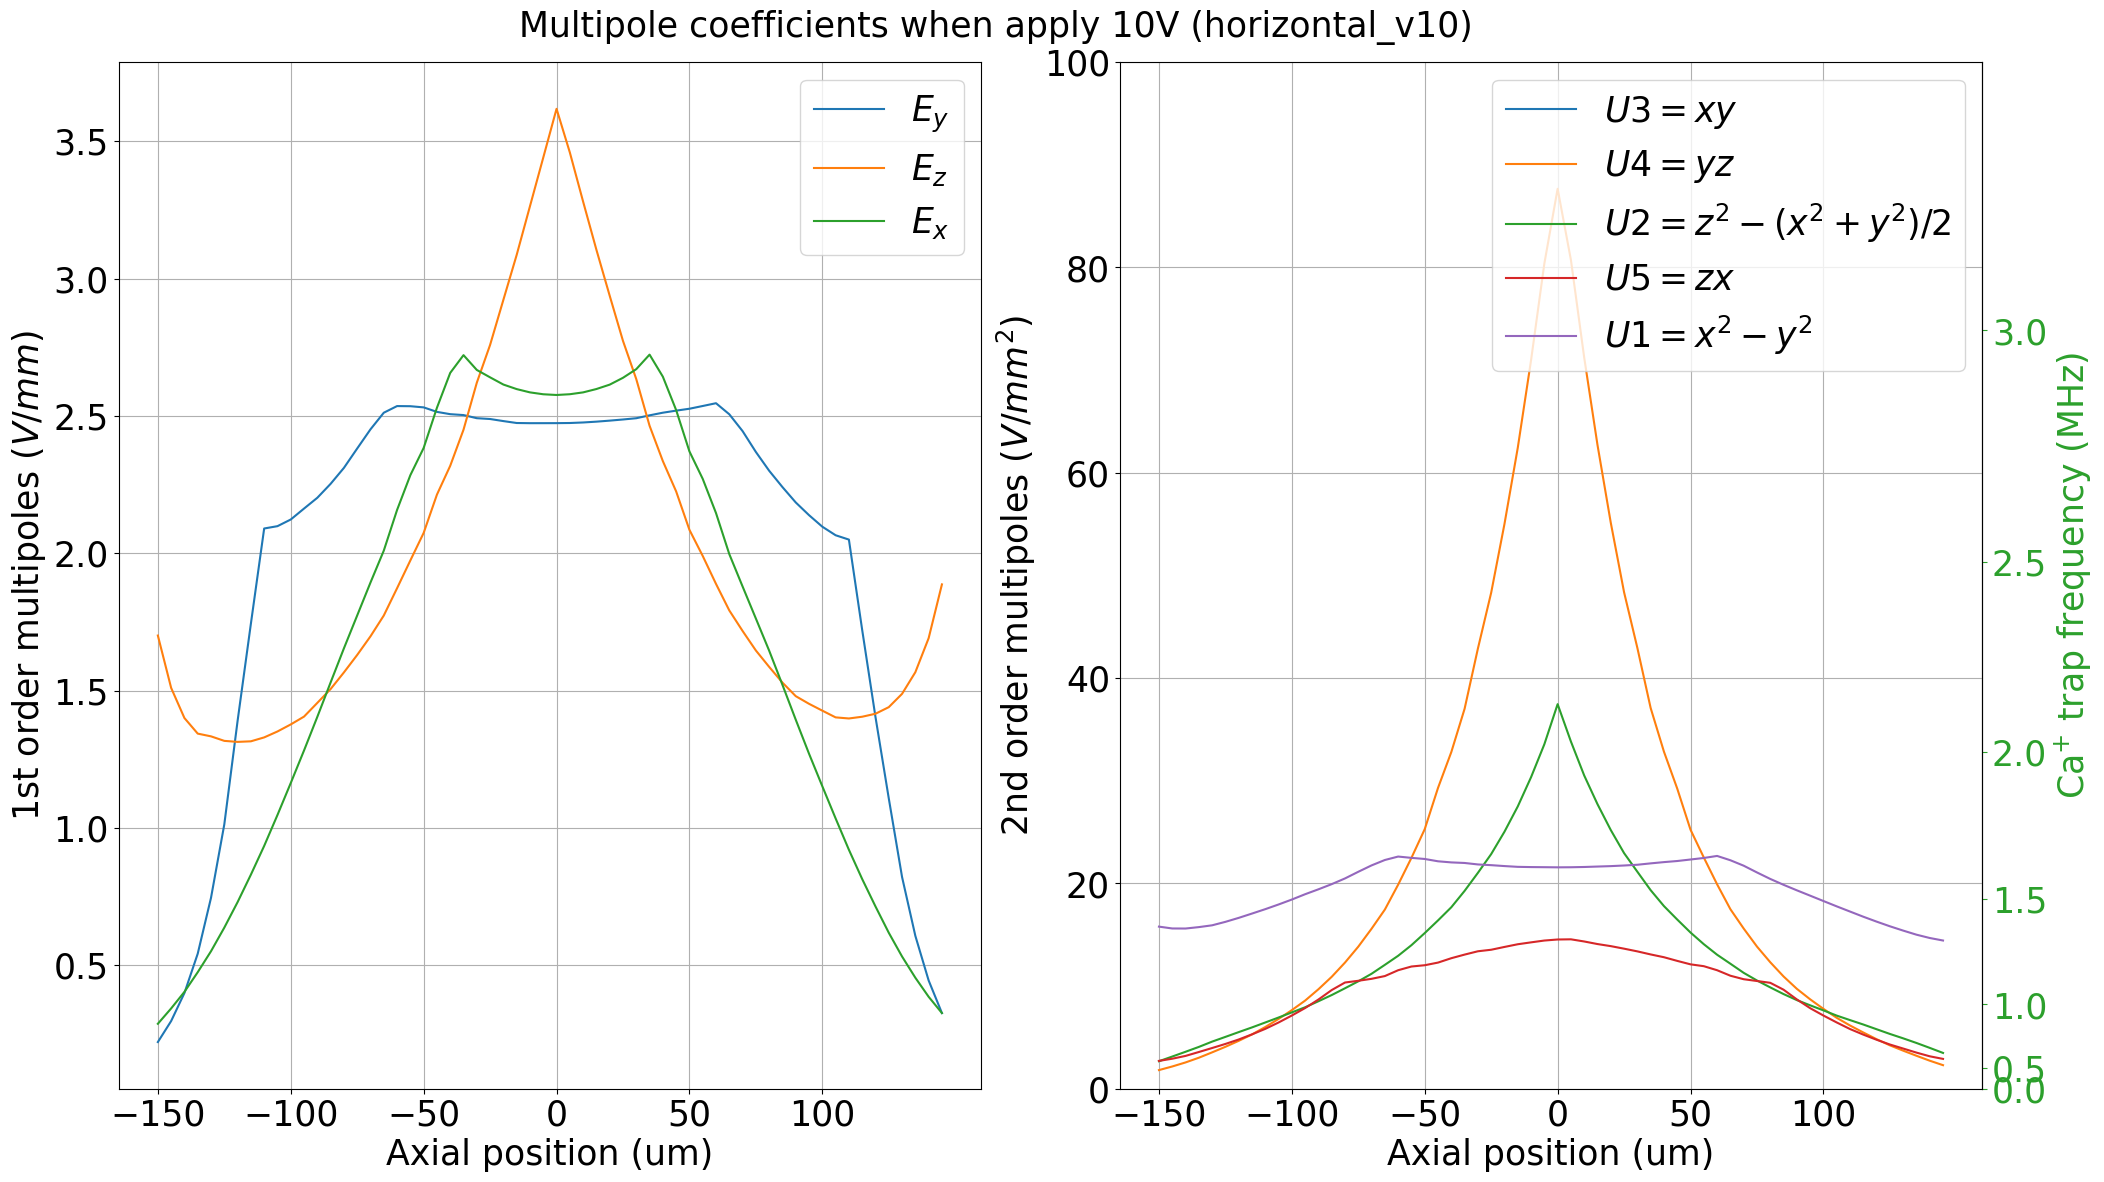

In [19]:
height_list = np.arange(-150,150,5)
numMUltipoles = len(used_multipoles)
Coeffs = pd.DataFrame()
for height in height_list:
    position1 = [0,0.192,height*1e-3]
    s.update_origin_roi(position1, roi)
    
    Coeffs_temp = pd.Series(dtype = 'float64')
    for key in used_multipoles:
        multipole_coeffs = pd.Series(np.zeros(len(used_multipoles)), index = used_multipoles)
        multipole_coeffs[key] = 1
        voltages = s.setMultipoles(multipole_coeffs)
        max_v = np.max(abs(voltages))
        Coeffs_temp[key] = 10/max_v
    
    Coeffs[height] = Coeffs_temp

# # switch from Ex, Ey, Ez to x, y, z convention (just discard the minus sign)    
# first_order_mapping_dict = {'Ex': 'x', 'Ey': 'y', 'Ez': 'z'}

size = 25
# plt.rc('xtick', labelsize=size)    # fontsize of the tick labels
# plt.rc('ytick', labelsize=size)    # fontsize of the tick labels
fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (20,12))
for mul in used_order1multipoles:
    ax1.plot(height_list, Coeffs.loc[mul], label = s.multipole_print_names[mul])
ax1.set_ylabel(r'1st order multipoles $(V/mm)$', fontsize = size)
ax1.set_xticks(np.arange(height_list[0],height_list[-1]+1,50))
ax1.set_xlabel('Axial position (um)', fontsize = size)
ax1.tick_params(labelsize = size)
ax1.legend(fontsize = size)

# ax1.set_ylim(0, 30) # set ylim

ax1.grid(True)

for mul in used_order2multipoles:
    ax2.plot(height_list, Coeffs.loc[mul], label = s.multipole_print_names[mul])
ax2.set_ylabel(r'2nd order multipoles $(V/mm^2)$', fontsize = size)
ax2.set_xticks(np.arange(height_list[0],height_list[-1]+1,50))
ax2.set_xlabel('Axial position (um)', fontsize = size)

ax2.set_ylim((0,100)) # set ylim

def U2_to_mhz(u2):
    m = 40.078 * 1.66e-27
    e = 1.6e-19
    return np.sqrt(2*e*u2*1e6/m) / 2 / np.pi / 1e6
def mhz_to_U2(mhz):
    m = 40.078 * 1.66e-27
    e = 1.6e-19
    return 4 * np.pi**2 * 1e12 * 1e-6 * m * mhz**2 / 2 / e

ax2.tick_params(labelsize = size)
ax2.legend(fontsize = size)
ax2.grid(True)
fig.suptitle('Multipole coefficients when apply 10V (horizontal_v10)', fontsize = size)
fig.tight_layout(pad=1)

secax = ax2.secondary_yaxis('right', functions = (U2_to_mhz, mhz_to_U2))
secax.tick_params(labelsize = size, colors = '#2ca02c')
secax.set_ylabel(r'$\mathrm{Ca}^{+}$ trap frequency (MHz)', fontsize = size, color = '#2ca02c')
# plt.show()

# plt.savefig('Multipole_coeffs_20v_rfbias.jpg', format = 'jpg', dpi = 300)

## Sr+

In [ ]:
height_list = np.arange(-150,150,5)
numMUltipoles = len(used_multipoles)
Coeffs = pd.DataFrame()
for height in height_list:
    position1 = [0,0.192,height*1e-3]
    s.update_origin_roi(position1, roi)
    
    Coeffs_temp = pd.Series(dtype = 'float64')
    for key in used_multipoles:
        multipole_coeffs = pd.Series(np.zeros(len(used_multipoles)), index = used_multipoles)
        multipole_coeffs[key] = 1
        voltages = s.setMultipoles(multipole_coeffs)
        max_v = np.max(abs(voltages))
        Coeffs_temp[key] = 10/max_v
    
    Coeffs[height] = Coeffs_temp

# # switch from Ex, Ey, Ez to x, y, z convention (just discard the minus sign)    
# first_order_mapping_dict = {'Ex': 'x', 'Ey': 'y', 'Ez': 'z'}

size = 25
# plt.rc('xtick', labelsize=size)    # fontsize of the tick labels
# plt.rc('ytick', labelsize=size)    # fontsize of the tick labels
fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (20,12))
for mul in used_order1multipoles:
    ax1.plot(height_list, Coeffs.loc[mul], label = s.multipole_print_names[mul])
ax1.set_ylabel(r'1st order multipoles $(V/mm)$', fontsize = size)
ax1.set_xticks(np.arange(height_list[0],height_list[-1]+1,50))
ax1.set_xlabel('Axial position (um)', fontsize = size)
ax1.tick_params(labelsize = size)
ax1.legend(fontsize = size)

# ax1.set_ylim(0, 30) # set ylim

ax1.grid(True)

for mul in used_order2multipoles:
    ax2.plot(height_list, Coeffs.loc[mul], label = s.multipole_print_names[mul])
ax2.set_ylabel(r'2nd order multipoles $(V/mm^2)$', fontsize = size)
ax2.set_xticks(np.arange(height_list[0],height_list[-1]+1,50))
ax2.set_xlabel('Axial position (um)', fontsize = size)

ax2.set_ylim((0,100)) # set ylim

def U2_to_mhz(u2):
    m = 87.62 * 1.66e-27
    e = 1.6e-19
    return np.sqrt(2*e*u2*1e6/m) / 2 / np.pi / 1e6
def mhz_to_U2(mhz):
    m = 87.62 * 1.66e-27
    e = 1.6e-19
    return 4 * np.pi**2 * 1e12 * 1e-6 * m * mhz**2 / 2 / e

ax2.tick_params(labelsize = size)
ax2.legend(fontsize = size)
ax2.grid(True)
fig.suptitle('Multipole coefficients when apply 10V (horizontal_v10)', fontsize = size)
fig.tight_layout(pad=1)

secax = ax2.secondary_yaxis('right', functions = (U2_to_mhz, mhz_to_U2))
secax.tick_params(labelsize = size, colors = '#2ca02c')
secax.set_ylabel(r'$\mathrm{Sr}^{+}$ trap frequency (MHz)', fontsize = size, color = '#2ca02c')
# plt.show()

# plt.savefig('Multipole_coeffs_20v_rfbias.jpg', format = 'jpg', dpi = 300)

# plot potential projection along x, y, z axis when apply voltage solution of a group of multipole coefficients

In [ ]:
def plot_1d(height, ey, ez, ex, u3, u4, u2, u5, u1):
    position1 = [0, 0.192, height*1e-3]
    s.update_origin_roi(position1, roi)
    multipole_coeffs = {'Ey': ey, 'Ez':ez, 'Ex': ex, 'U3':u3, 'U4':u4, 'U2':u2, 'U5':u5, 'U1':u1}
    voltages = s.setMultipoles(multipole_coeffs)
    potential_roi = s.potentialControl_roi(voltages)
    potential_regen = s.potentialControl_regen(voltages)
    
    potential_z_roi = potential_roi.sel(x = 0, y = 0.192)
    potential_z_regen = potential_regen.sel(x = 0, y = 0.192)
    potential_x_roi = potential_roi.sel(y = 0.192, z = height*1e-3, method = 'nearest')
    potential_x_regen = potential_regen.sel(y = 0.192, z = height*1e-3, method = 'nearest')
    potential_y_roi = potential_roi.sel(x = 0, z = height*1e-3, method = 'nearest')
    potential_y_regen = potential_regen.sel(x = 0, z = height*1e-3, method = 'nearest')
    
    offset = potential_roi.sel(x = 0, y = 0.192, z = height*1e-3, method = 'nearest') - potential_regen.sel(x = 0, y = 0, z = height*1e-3, method = 'nearest')
    print(offset)
    
    fsize = 20
    
    fig1, ax = plt.subplots(3,1,figsize = (10,20))
    ax[0].set_title('Potential along X', fontsize = fsize)
    ax[0].plot(potential_x_roi.x, potential_x_roi, label = 'original')
    ax[0].plot(potential_x_regen.x, potential_x_regen + offset, label = 'regenerated + offset')
    ax[0].set_xlabel('X (mm)', fontsize = fsize)
    ax[0].set_ylabel('V (v)', fontsize = fsize)
    ax[0].legend(fontsize = fsize)
    
    ax[1].set_title('Potential along Y', fontsize = fsize)
    ax[1].plot(potential_y_roi.y, potential_y_roi, label = 'original')
    ax[1].plot(potential_y_regen.y, potential_y_regen + offset, label = 'regenerated + offset')
    ax[1].set_xlabel('Y (mm)', fontsize = fsize)
    ax[1].set_ylabel('V (v)', fontsize = fsize)
    ax[1].legend(fontsize = fsize)
    
    ax[2].set_title('Potential along Z', fontsize = fsize)
    ax[2].plot(potential_z_roi.z, potential_z_roi, label = 'original')
    ax[2].plot(potential_z_regen.z, potential_z_regen + offset, label = 'regenerated + offset')
    ax[2].set_xlabel('Z (mm)', fontsize = fsize)
    ax[2].set_ylabel('V (v)', fontsize = fsize)
    ax[2].legend(fontsize = fsize)
    
    fig1.tight_layout(pad=1)
    
    plt.show()
    
interactive_plot = interactive(plot_1d, height = (-150, 150), ez=(-1, 1, 0.1), ex=(-1, 1, 0.1), ey=(-1, 1, 0.1), u2 = (0 , 40), u5 = (-10, 10), u4 = (-10, 10), u1 = (-10, 10), u3 = (-10, 10))
output = interactive_plot.children[-1]
output.layout.height = '1600px'
interactive_plot

# plot potential projection in xy plane when apply voltage solution of a group of multipole coefficients

In [ ]:
def plot_U2(height, ey, ez, ex, u3, u4, u2, u5, u1):
    position1 = [0, 0.192, height*1e-3]
    s.update_origin_roi(position1, roi)
    multipole_coeffs = {'Ey': ey, 'Ez':ez, 'Ex': ex, 'U3':u3, 'U4':u4, 'U2':u2, 'U5':u5, 'U1':u1}
    voltages = s.setMultipoles(multipole_coeffs)
    potential_roi = s.potentialControl_roi(voltages)
    potential_regen = s.potentialControl_regen(voltages)
    
    potential_xy_roi = potential_roi.sel(z = height*1e-3, l = '')
    potential_xy_regen = potential_regen.sel(z = height*1e-3, l = '')
    
    
    fsize = 20
    
    fig1 = plt.figure(figsize = (20,16))
    grid = plt.GridSpec(2,2)
    ax1 = fig1.add_subplot(grid[0,0])
    ax2 = fig1.add_subplot(grid[0,1])
    ax3 = fig1.add_subplot(grid[1,:])
    ax1.set_title('Simulated potential', fontsize = fsize)
    levels1 = np.linspace(np.amin(potential_xy_roi),np.amax(potential_xy_roi),100)
    plot1 = ax1.contourf(potential_xy_roi.x, potential_xy_roi.y, potential_xy_roi, levels1, cmap = plt.cm.viridis)
    plot1_line = ax1.contour(potential_xy_roi.x, potential_xy_roi.y, potential_xy_roi, colors = 'w')
#     ax1.clabel(plot1_line, inline = 1, fontsize = fsize)
    ax1.clabel(plot1_line, colors = 'w', fmt = '%2.3f', fontsize=fsize)
    ax1.set_xlabel('X (mm)', fontsize = fsize)
    ax1.set_ylabel('Y (mm)', fontsize = fsize)
    plt.colorbar(plot1, ax = ax1)
    
    ax2.set_title('Regenerated potential', fontsize = fsize)
    levels2 = np.linspace(np.amin(potential_xy_regen),np.amax(potential_xy_regen),100)
    plot2 = ax2.contourf(potential_xy_regen.x, potential_xy_regen.y, potential_xy_regen, levels2, cmap = plt.cm.viridis)
    plot2_line = ax2.contour(potential_xy_regen.x, potential_xy_regen.y, potential_xy_regen, colors = 'w')
#     ax2.clabel(plot2, inline = 1, fontsize = fsize)
    ax2.clabel(plot2_line, colors = 'w', fmt = '%2.3f', fontsize=fsize)
    ax2.set_xlabel('X (mm)', fontsize = fsize)
    plt.colorbar(plot2, ax = ax2)
    
    coeffs = s.setVoltages(voltages)
#     print(coeffs.index)
    ax3.bar(range(len(coeffs)),np.asarray(coeffs))
    max_coeff = np.max(coeffs)
    min_coeff = np.min(coeffs)
    margin = (max_coeff - min_coeff)*0.1
    ymax = max_coeff + margin
    ymin = min_coeff - margin
    ax3.set_ylim(ymin, ymax)
    add_value_labels(ax3)
    ax3.set_xticks(range(len(coeffs)))
    ax3.set_xticklabels(s.multipole_names, rotation = -90, fontsize = fsize)
    plt.show()
    
interactive_plot = interactive(plot_U2, height = (-150, 150), ez=(-1, 1, 0.1), ex=(-1, 1, 0.1), ey=(-1, 1, 0.1), u2 = (0 , 40), u5 = (-10, 10), u4 = (-10, 10), u1 = (-10, 10), u3 = (-10, 10))
output = interactive_plot.children[-1]
output.layout.height = '800px'
interactive_plot

In [ ]:
position1 = [0,0.192,0]
s.update_origin_roi(position1, roi)

for multip in s.used_multipoles:
    multipole_coeffs = {'Ey':0, 'Ez':0, 'Ex': 0, 'U3':0, 'U2':0, 'U5':0, 'U1':0, 'U4':0} # change this later to be compatible with used multipoles
    multipole_coeffs[multip] = 1
    voltages = s.setMultipoles(multipole_coeffs)
    print(multip, ': ',  voltages.values)

In [ ]:
s.used_multipoles